# Iris Classification Baseline

A reproducible baseline using a stratified split and Random Forest.

In [1]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

In [2]:
iris = load_iris(as_frame=True)
X, y = iris.data, iris.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
model = RandomForestClassifier(n_estimators=100, max_depth=4, random_state=42)
model.fit(X_train, y_train)
pred = model.predict(X_test)
print('Accuracy:', round(accuracy_score(y_test, pred), 4))
print('Weighted F1:', round(f1_score(y_test, pred, average='weighted'), 4))
print(classification_report(y_test, pred, target_names=iris.target_names))

Accuracy: 0.9667
Weighted F1: 0.9666
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



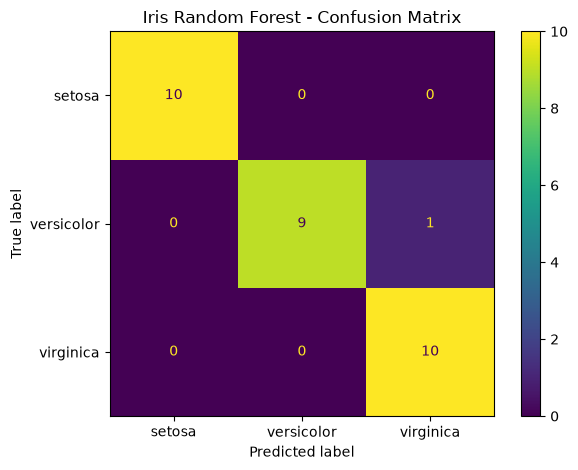

In [3]:
ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=iris.target_names)
plt.title('Iris Random Forest - Confusion Matrix')
plt.tight_layout()
plt.show()

**Reproducibility:** random_state=42 and stratified splitting make the train/test partition repeatable.